# trunc-tetra-4 — тесты

Порядок как в `src/geom_tests.py`. **Шаг 0 обязателен** (один усечённый тетраэдр → matplotlib + STL).

Ядро: то же `.venv`, что для `stlgen`.

In [1]:
import sys
from pathlib import Path

# Папка trunc-tetra-4: ищем вверх по дереву, чтобы работало при любом cwd ядра
def _find_root(start: Path) -> Path:
    for d in [start, *start.parents]:
        if (d / "src" / "geom_tests.py").is_file():
            return d
    raise RuntimeError(f"Не найден корень trunc-tetra-4 выше {start}")

ROOT = _find_root(Path.cwd().resolve())
SRC = ROOT / "src"
STLGEN = ROOT.parent
OUT = ROOT / "out"
OUT.mkdir(exist_ok=True)

for p in (str(STLGEN), str(SRC)):
    if p not in sys.path:
        sys.path.insert(0, p)

print("ROOT", ROOT)
print("STLGEN", STLGEN)

ROOT /Users/vorobevd/techHub/SLS/sls-models/stlgen/trunc-tetra-4
STLGEN /Users/vorobevd/techHub/SLS/sls-models/stlgen


## Шаг 0 — один усечённый тетраэдр

Тест: Усечённый тетраэдр

Параметры: a=40.0, half_height=10.0

✓ Создан полиэдр: ConvexPolyhedron(planes=6, vertices=0, faces=0)
  Плоскостей: 6 (должно быть 6)
  Троек вершин: 8 (должно быть 8)
  h0 несрезанного тетраэдра: 14.1421

Вычисление вершин...
✓ Вершины построены: 8 (ожидается 8)

Построение выпуклой оболочки...
✓ Convex hull: 12 треугольных граней

Экспорт в STL: trunc_tet_a40.0_h10.0.stl
ASCII-STL written: /Users/vorobevd/techHub/SLS/sls-models/stlgen/trunc-tetra-4/out/trunc_tet_a40.0_h10.0.stl
  • Unique vertices: 8
  • Triangles: 12
✓ Размер файла: 3539 байт

Визуализация...
✓ Визуализация сохранена: trunc_tet_a40.0_h10.0.png
  Отображение графика... (закройте окно для продолжения)


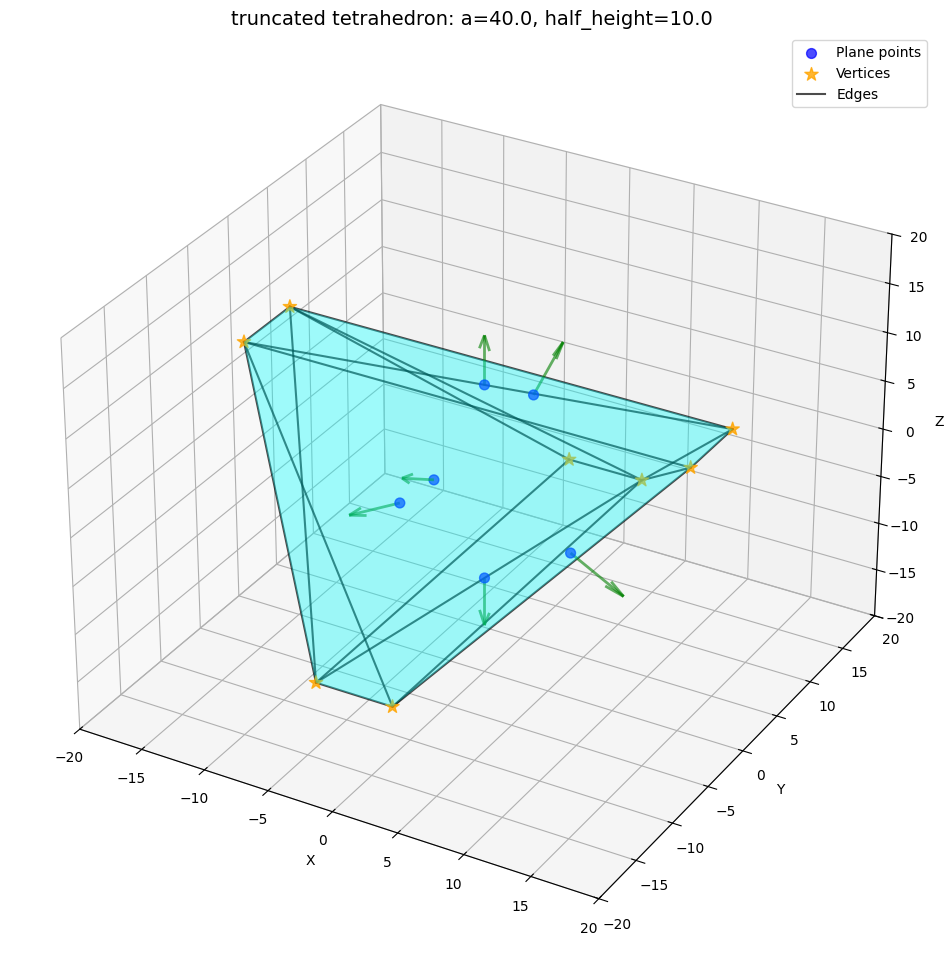


✅ test_truncated_tetrahedron пройден


In [3]:
from geom_tests import test_truncated_tetrahedron

test_truncated_tetrahedron(show=True)  # show=False, если окно не нужно

In [4]:
# Интерактивное окно matplotlib (вращение мышью), а не статичная картинка в ячейке.
# widget (ipympl) — встроенное интерактивное; qt — отдельное окно.
try:
    get_ipython().run_line_magic("matplotlib", "widget")
    print("backend: widget")
except Exception as e:
    print("widget недоступен:", e)
    try:
        get_ipython().run_line_magic("matplotlib", "qt")
        print("backend: qt")
    except Exception as e2:
        print("qt недоступен:", e2)

from geom_tests import test_truncated_tetrahedron

test_truncated_tetrahedron(show=True, interactive_backend=True)

widget недоступен: 'widget is not a recognised GUI loop or backend name
qt недоступен: Failed to import any of the following Qt binding modules: PyQt6, PySide6, PyQt5, PySide2


TypeError: test_truncated_tetrahedron() got an unexpected keyword argument 'interactive_backend'

## Шаг 1 — четыре типа блоков

In [5]:
from geom_tests import test_four_block_types

test_four_block_types(show=False)

Тест: четыре типа блоков
  DOUBLE_2H_s1: vertices=8, faces=12
ASCII-STL written: /Users/vorobevd/techHub/SLS/sls-models/stlgen/trunc-tetra-4/out/DOUBLE_2H_s1.stl
  • Unique vertices: 8
  • Triangles: 12
  HALF_H_s1: vertices=8, faces=12
ASCII-STL written: /Users/vorobevd/techHub/SLS/sls-models/stlgen/trunc-tetra-4/out/HALF_H_s1.stl
  • Unique vertices: 8
  • Triangles: 12
  HALF_H_s-1: vertices=8, faces=12
ASCII-STL written: /Users/vorobevd/techHub/SLS/sls-models/stlgen/trunc-tetra-4/out/HALF_H_s-1.stl
  • Unique vertices: 8
  • Triangles: 12
  LARGE_H_s1: vertices=8, faces=12
ASCII-STL written: /Users/vorobevd/techHub/SLS/sls-models/stlgen/trunc-tetra-4/out/LARGE_H_s1.stl
  • Unique vertices: 8
  • Triangles: 12
  SMALL_H_s1: vertices=8, faces=12
ASCII-STL written: /Users/vorobevd/techHub/SLS/sls-models/stlgen/trunc-tetra-4/out/SMALL_H_s1.stl
  • Unique vertices: 8
  • Triangles: 12
✅ test_four_block_types пройден


## Шаг 2 — половинки совпадают с двойным по Z

In [6]:
from geom_tests import test_halves_match_double

test_halves_match_double()

Тест: две половинки = двойной по Z
  DOUBLE Z: (np.float64(-10.0), np.float64(10.0))
  HALF+  Z: (np.float64(-0.0), np.float64(10.0))
  HALF-  Z: (np.float64(-10.0), np.float64(0.0))
  union  Z: (np.float64(-10.0), np.float64(10.0))
✅ test_halves_match_double пройден


## Шаг 3 — placement

`nx_bl`×`ny_bl` — число **двойных** блоков; `nz` — **чётное** число слоёв `H`.

Проверки: 4 типа присутствуют; все z в пределах пластины; цвет клетки ↔ тип; чётные ряды смещены на `H`; белые чередуют `LARGE/SMALL` по `k`; половинки только на торцах.

Консоль: `python src/geom_tests.py --steps 3`.

In [ ]:
# Placement: nx_bl×ny_bl двойных блоков, nz — чётное число слоёв H.
from geom_tests import test_placement

test_placement(nx_bl=3, ny_bl=3, nz=6, H=10.0, L=20.0, alpha_deg=25.0)

## Шаг 4 — слой + matplotlib + STL

In [ ]:
# Слой: визуализация (крутить — в окне) + общий STL.
# Для интерактива сначала выполните ячейку шага 0 с %matplotlib widget / qt.
from geom_tests import test_layer_gen

test_layer_gen(
    is_visualized=True,
    interactive_backend=False,   # True — попробует Qt/Tk окно
    nx_bl=3, ny_bl=3, nz=6,
    H=10.0, L=20.0, alpha_deg=25.0,
    viz_scale=0.99,              # −1% к линейному размеру, только картинка
)


## Шаг 5 — непересечение блоков

Проверка, что внутренние объёмы не пересекаются (консервативно: по XY-шагу и Z-интервалам).

Консоль: `python src/geom_tests.py --steps 5`.

## Шаг 9 — слой в разрезе

Удаляем все блоки, чей **центр** лежит по одну сторону от плоскости. Остаётся «половина параллелепипеда», срезанная под углом — видно сборку внутри.

Консоль:

```bash
python src/geom_tests.py --steps 9 --window
python src/geom_tests.py --steps 9 --cut-nx 1 --cut-ny 0 --cut-nz 0.4 --window
```


In [ ]:
from geom_tests import test_layer_cut

test_layer_cut(
    is_visualized=True,
    interactive_backend=False,
    nx_bl=3, ny_bl=3, nz=6,
    H=10.0, L=20.0, alpha_deg=25.0,
    # косая плоскость через центр; keep_negative=True → n·(c−p) ≤ 0
    plane_normal=None,
    keep_negative=True,
)


In [7]:
from geom_tests import test_no_overlap

test_no_overlap(nx_bl=3, ny_bl=3, nz=6, H=10.0, L=20.0, alpha_deg=25.0)

ImportError: cannot import name 'test_no_overlap' from 'geom_tests' (/Users/vorobevd/techHub/SLS/sls-models/stlgen/trunc-tetra-4/src/geom_tests.py)

## Эталонный узел блоков как на фото

Именованный тест собирает узел структуры: один `DOUBLE_2H`, четыре `SMALL_H` снизу и четыре `LARGE_H` сверху. Дополнительно сохраняется правильный верхний торец с нижней половиной виртуального двойного над пластиной.

```bash
python src/geom_tests.py --test reference-block-joint --H 3 --L 2 --window
```


Результаты теста:

- `out/reference_block_joint.png/.stl` — внутренний узел;
- `out/reference_end_cap_joint.png/.stl` — исправленный верхний торец;
- проверки состава, смещений `±H/2` и ориентации `HALF` выполняются автоматически.


In [ ]:
from geom_tests import test_reference_block_joint

test_reference_block_joint(
    is_visualized=True,
    interactive_backend=False,
    H=3.0,
    L=2.0,
    alpha_deg=25.0,
    viz_scale=0.97,
)


In [ ]:
# Второй PNG/STL верхнего торца создаётся тем же test_reference_block_joint().


## Заглушка STEP

In [ ]:
from export_step import export_step

try:
    export_step([], "out/dummy.step")
except NotImplementedError as e:
    print("ok stub:", e)